# Raio-X Comercial · Análise exploratória dos dados (EDA)

**O que é este notebook.** A olhada nos dados da CVM *antes* de usá-los: o que falta (nulos), como os indicadores se
espalham (distribuições), quem foge do normal (extremos) e o que a base cobre (anos e setores). Cada gráfico vem com o que
ele mostra e com a decisão do projeto que saiu dele.

**De onde vêm os dados.** As DFP (demonstrações financeiras anuais) das companhias abertas, no portal de dados abertos da CVM:

1. `scripts/carregar_dfp.py` baixa as DFP de 3 anos, aplica as regras de limpeza (`raiox/limpeza.py`) e grava
   `data/contas.csv` (uma linha por empresa, ano e conta) e o PostgreSQL;
2. `scripts/indicadores.py` calcula os 6 indicadores do último ano e grava `data/indicadores.csv` (contrato C2, uma linha por
   empresa) e a tabela `indicadores` no PostgreSQL.

Este notebook lê os dois CSV (o mesmo conteúdo do banco), então roda sem o PostgreSQL ligado.

**Como rodar.** Com a `data/` real (os 2 scripts acima, ou o zip do Drive), "Restart & Run All": os 4 gráficos são gravados em
`docs/graficos/eda_*.png`. Sem a `data/`, ou com `RAIOX_DADOS=falsos`, ele usa os dados falsos de `falsos/` (como o resto do
projeto) e não grava nenhum PNG. O teste `tests/test_eda.py` roda o notebook inteiro com os falsos.

**Requisito do professor:** `guia_projeto_final.pdf`, §1 (eixo 1: "limpeza, EDA") e §2 ("Visualização explicativa dos
dados (usando Matplotlib/Seaborn ou dashboards)"); `requisitos_projeto.MD`, Machine Learning ("realizar a limpeza, análise
e transformações dos dados").

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, PercentFormatter

# A raiz do repositório é a pasta que tem raiox/ (o notebook pode ser aberto de notebooks/ ou da raiz)
RAIZ = Path.cwd().resolve()
while not (RAIZ / "raiox").is_dir():
    if RAIZ.parent == RAIZ:
        raise FileNotFoundError("Abra o notebook de dentro do repositório (não achei a pasta raiox/).")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

# Do código do projeto: a leitura da tabela (dados reais ou falsos), o corte de receita do K-means
# e os limites da checagem. Importados, e não copiados, para o notebook nunca discordar do código.
from raiox import checagem, segmentos  # noqa: E402

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Cores: azul = o dado comum; laranja = o que chama atenção; cinza = "outros"
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#898781"
TINTA, TINTA_2, FUNDO = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "font.size": 9,
})
PASTA_GRAFICOS = RAIZ / "docs" / "graficos"


def reais(valor, _posicao=None):
    """Valor em R$ curto, para eixos e rótulos: R$ 10 mi, R$ 1,5 bi."""
    for limite, sufixo in [(1e12, "tri"), (1e9, "bi"), (1e6, "mi"), (1e3, "mil")]:
        if abs(valor) >= limite:
            return f"R$ {valor / limite:.3g} {sufixo}".replace(".", ",")
    return f"R$ {valor:.3g}".replace(".", ",")


def milhar(n):
    """384591 -> 384.591"""
    return f"{n:,}".replace(",", ".")


def salvar(fig, nome):
    """Grava o PNG em docs/graficos/. Com os dados falsos não grava: o PNG do projeto é sempre dos dados reais."""
    if FALSOS:
        print(f"(dados falsos: {nome} não foi gravado)")
        return
    fig.savefig(PASTA_GRAFICOS / nome, dpi=120, bbox_inches="tight")
    print(f"gravado: docs/graficos/{nome}")

## 1. Os dados

Duas tabelas. A `contas.csv` tem as contas de cada empresa em cada ano, já limpas. A `indicadores.csv` tem uma linha por
empresa, com os 6 indicadores do último ano, e é a tabela que o raio-x, o K-means e a tela usam.

In [2]:
indicadores, FALSOS = segmentos.carregar_indicadores()     # data/indicadores.csv (ou a tabela falsa)
if FALSOS:
    contas = pd.read_csv(RAIZ / "falsos" / "contas_falsas.csv", dtype={"cd_conta": str})
else:
    contas = pd.read_csv(RAIZ / "data" / "contas.csv", dtype={"cd_conta": str})

ANO = int(indicadores["ano"].max())
print("usando dados falsos?", FALSOS)
print(f"contas.csv:      {milhar(len(contas))} linhas, {contas['cd_cvm'].nunique()} empresas, "
      f"anos {sorted(contas['ano'].unique().tolist())}")
print(f"indicadores.csv: {len(indicadores)} empresas, uma linha cada, ano {ANO}")
print("\nlinhas da contas.csv por demonstração (DRE = resultado, BPA = ativo, BPP = passivo e patrimônio):")
print(contas["demonstracao"].value_counts().to_string())

usando dados falsos? False
contas.csv:      384.591 linhas, 595 empresas, anos [2023, 2024, 2025]
indicadores.csv: 595 empresas, uma linha cada, ano 2025

linhas da contas.csv por demonstração (DRE = resultado, BPA = ativo, BPP = passivo e patrimônio):
demonstracao
BPP    205003
BPA    119400
DRE     60188


In [3]:
indicadores.head()

,cd_cvm,nome,setor,ano,receita,receita_2a_antes,cresc_2a,margem_ebit,margem_liquida,ativo_total,endividamento,origem,versao
0,23396,AEGEA SANEAMENTO E PARTICIPAÇÕES S.A.,"Saneamento, Serv. Água e Gás",2025,1.878047e+10,8.806540e+09,1.132559,0.345483,0.068161,5.537360e+10,0.915220,con,2
1,25283,AERIS IND. E COM. DE EQUIP. PARA GER. DE ENG. ...,"Máquinas, Equipamentos, Veículos e Peças",2025,7.460060e+08,2.831915e+09,-0.736572,-0.677279,-1.208051,1.613490e+09,1.431543,con,1
2,22179,AFLUENTE TRANSMISSÃO DE ENERGIA ELÉTRICA S/A,Energia Elétrica,2025,4.916300e+07,6.730700e+07,-0.269571,0.660232,0.484714,3.437230e+08,0.280397,ind,1
3,25194,ALARES INTERNET PARTICIPAÇÕES S/A,Emp. Adm. Part. - Telecomunicações,2025,9.389030e+08,5.678520e+08,0.653429,0.140344,-0.119054,2.374142e+09,0.816235,con,1
4,21032,ALGAR TELECOM S/A,Telecomunicações,2025,2.931979e+09,2.746728e+09,0.067444,0.090954,-0.067205,6.086063e+09,0.841837,con,1


## 2. Nulos: o que falta e por quê

**A regra do projeto (regra 7, `raiox/limpeza.py` e `scripts/indicadores.py`): o que falta fica vazio.** Não vira zero e
não é estimado. Um zero no lugar de um vazio viraria "crescimento de −100%" ou "margem de 0%", e o raio-x mostraria ao
vendedor um número que não existe.

Os 6 indicadores usam 5 contas do último ano (receita, EBIT, lucro, ativo total e patrimônio líquido) e, para o crescimento,
a receita de 2 anos antes. Primeiro, se todas as empresas têm as 5 contas:

In [4]:
INDICADORES = ["receita", "cresc_2a", "margem_ebit", "margem_liquida", "ativo_total", "endividamento"]
NOMES = {"receita": "Receita", "cresc_2a": "Crescimento em 2 anos", "margem_ebit": "Margem EBIT",
         "margem_liquida": "Margem líquida", "ativo_total": "Ativo total", "endividamento": "Endividamento"}
CONTAS = {"3.01": "receita", "3.05": "EBIT", "3.11": "lucro", "1": "ativo total", "2.03": "patrimônio líquido"}

ultimo_ano = contas[contas["ano"] == ANO]
empresas_no_ano = ultimo_ano["cd_cvm"].nunique()
print(f"Empresas com cada conta preenchida em {ANO}:")
for conta, nome in CONTAS.items():
    tem = ultimo_ano.loc[(ultimo_ano["cd_conta"] == conta) & ultimo_ano["valor"].notna(), "cd_cvm"].nunique()
    print(f"  {nome:<20} ({conta:>4}): {tem} de {empresas_no_ano}")

vazios_contas = contas[contas["valor"].isna()]
print(f"\nValores vazios na contas.csv: {len(vazios_contas)} de {milhar(len(contas))} "
      "(valor que faltava ou que vinha diferente em duas linhas da CVM: regra 7)")
print(vazios_contas[["nome", "ano", "demonstracao", "cd_conta", "ds_conta"]].to_string(index=False))

Empresas com cada conta preenchida em 2025:
  receita              (3.01): 595 de 595
  EBIT                 (3.05): 595 de 595
  lucro                (3.11): 595 de 595
  ativo total          (   1): 595 de 595
  patrimônio líquido   (2.03): 595 de 595

Valores vazios na contas.csv: 11 de 384.591 (valor que faltava ou que vinha diferente em duas linhas da CVM: regra 7)
                                         nome  ano demonstracao      cd_conta                                               ds_conta
   BRISANET SERVIÇOS DE TELECOMUNICAÇÕES S.A. 2023          DRE       3.08.01                                               Corrente
   BRISANET SERVIÇOS DE TELECOMUNICAÇÕES S.A. 2023          DRE       3.08.02                                               Diferido
                   AUTOMOB PARTICIPAÇÕES S.A. 2023          DRE          3.02                  Custo dos Bens e/ou Serviços Vendidos
                   AUTOMOB PARTICIPAÇÕES S.A. 2023          DRE          3.03                  

E nos indicadores: quantas empresas ficam sem cada um, e por quê.

In [5]:
vazios = indicadores[INDICADORES].isna().sum()
print("Empresas sem o indicador:")
print(vazios.rename(NOMES).to_string())

# O crescimento compara a receita de hoje com a de 2 anos antes. Ele fica vazio em 2 casos:
motivos = pd.Series({
    f"sem receita de {ANO - 2}\nna base": int(indicadores["receita_2a_antes"].isna().sum()),
    f"receita de {ANO - 2} zero ou negativa\n(regra 7: não divide)": int((indicadores["receita_2a_antes"] <= 0).sum()),
})
print("\nPor que o crescimento fica vazio:")
print(motivos.rename(lambda s: s.replace("\n", " ")).to_string())
assert motivos.sum() == vazios["cresc_2a"], "há crescimento vazio por outro motivo: investigar antes de seguir"

Empresas sem o indicador:
Receita                   0
Crescimento em 2 anos    30
Margem EBIT               0
Margem líquida            0
Ativo total               0
Endividamento             0

Por que o crescimento fica vazio:
sem receita de 2023 na base                               23
receita de 2023 zero ou negativa (regra 7: não divide)     7


gravado: docs/graficos/eda_1_nulos.png


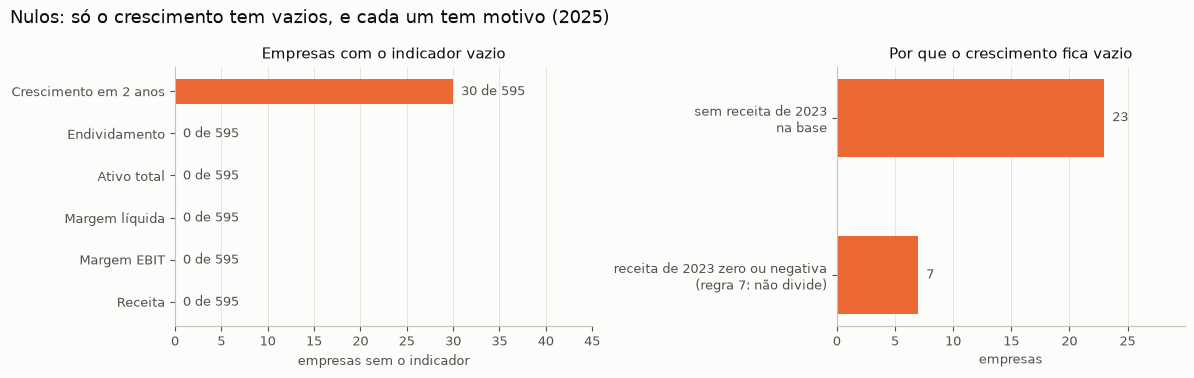

In [6]:
fig, (esq, dir_) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})

ordem = vazios.sort_values()
esq.barh([NOMES[c] for c in ordem.index], ordem.values, height=0.6,
         color=[LARANJA if v > 0 else AZUL for v in ordem.values])
for i, v in enumerate(ordem.values):
    esq.text(v, i, f"  {v} de {len(indicadores)}", va="center", color=TINTA_2)
esq.set_xlim(0, max(ordem.max(), 1) * 1.5)
esq.set_xlabel("empresas sem o indicador")
esq.set_title("Empresas com o indicador vazio")
esq.grid(axis="y", visible=False)

dir_.barh(motivos.index[::-1], motivos.values[::-1], height=0.5, color=LARANJA)
for i, v in enumerate(motivos.values[::-1]):
    dir_.text(v, i, f"  {v}", va="center", color=TINTA_2)
dir_.set_xlim(0, max(motivos.max(), 1) * 1.3)
dir_.set_xlabel("empresas")
dir_.set_title("Por que o crescimento fica vazio")
dir_.grid(axis="y", visible=False)

fig.suptitle(f"Nulos: só o crescimento tem vazios, e cada um tem motivo ({ANO})", x=0.01, ha="left",
             fontsize=13, color=TINTA)
fig.tight_layout()
salvar(fig, "eda_1_nulos.png")
plt.show()

**O que o gráfico mostra.** Todas as empresas têm as 5 contas do último ano: a regra 6 (`filtrar_empresas_com_receita`,
`raiox/limpeza.py`) já deixou só quem tem receita de venda positiva. O único indicador com vazios é o crescimento, e por
dois motivos: a empresa não tem a DFP de 2 anos antes na base (a conta não existia ou ela ainda não reportava), ou a receita
daquele ano era zero (dividir por zero não vale). Os poucos vazios da `contas.csv` são de anos ou contas que os indicadores
não usam, por isso nenhuma margem fica vazia.

**Decisão.** O vazio continua vazio até a tela: o raio-x mostra "sem dado" em vez de inventar um crescimento (`raiox/ia.py`).
Só dentro do K-means, para calcular os grupos, o vazio recebe a mediana (`matriz()`, `raiox/segmentos.py`); o número da tela não muda.

## 3. Distribuições: como os 6 indicadores se espalham

Receita e ativo vão de milhares a centenas de bilhões de reais, por isso usam escala logarítmica (cada marca do eixo é 10
vezes a anterior). Os 4 indicadores em % usam os limites da checagem (`raiox/checagem.py`); o que passa do limite fica
encostado na borda do gráfico e é contado no título.

gravado: docs/graficos/eda_2_distribuicoes.png


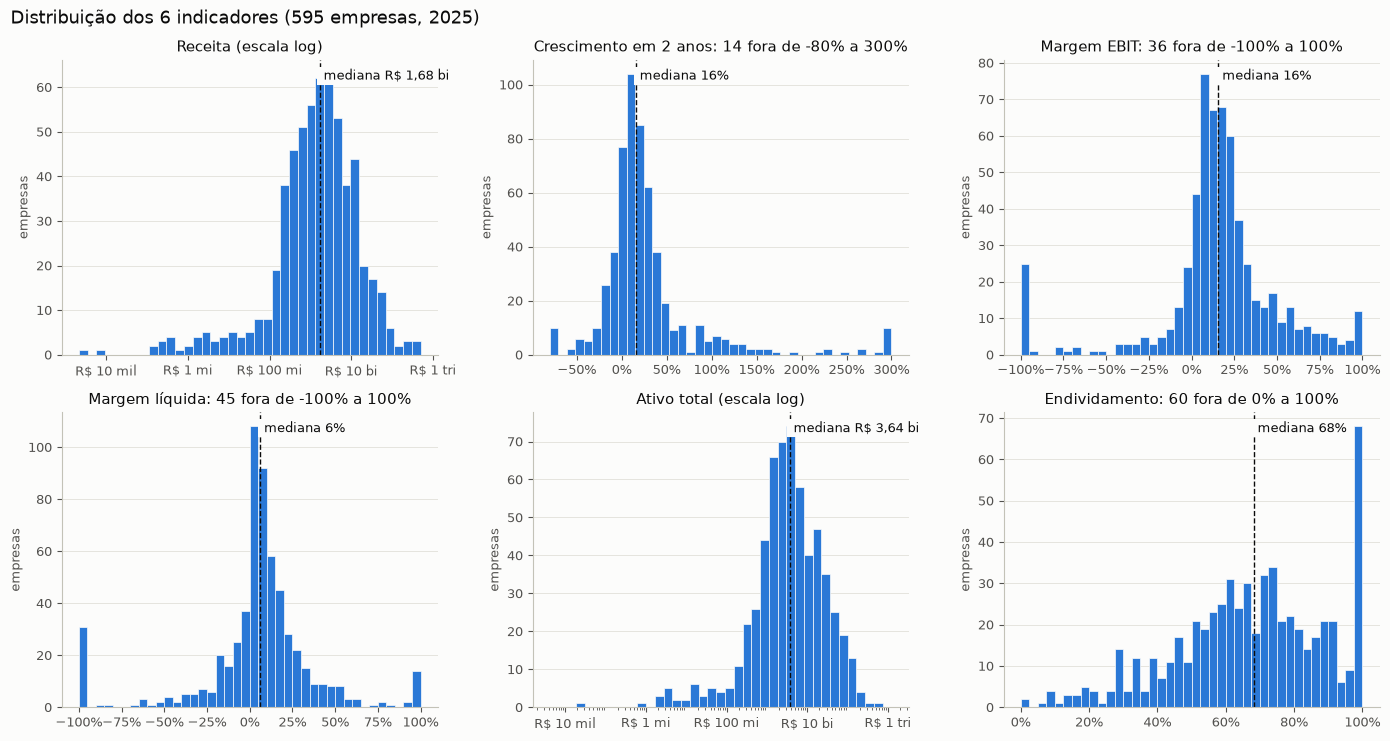

In [7]:
FAIXAS = {
    "cresc_2a": (checagem.CRESC_MIN, checagem.CRESC_MAX),
    "margem_ebit": (checagem.MARGEM_MIN, checagem.MARGEM_MAX),
    "margem_liquida": (checagem.MARGEM_MIN, checagem.MARGEM_MAX),
    "endividamento": (0.0, 1.0),          # acima de 100%: patrimônio líquido negativo (checagem)
}
porcento = PercentFormatter(xmax=1, decimals=0)

fig, eixos = plt.subplots(2, 3, figsize=(14, 7.5))
for eixo, coluna in zip(eixos.flatten(), INDICADORES):
    valores = indicadores[coluna].dropna()
    mediana = valores.median()
    if coluna in ("receita", "ativo_total"):
        positivos = valores[valores > 0]
        caixas = np.logspace(np.log10(positivos.min()), np.log10(positivos.max()), 40)
        eixo.hist(positivos, bins=caixas, color=AZUL, edgecolor=FUNDO, linewidth=0.5)
        eixo.set_xscale("log")
        eixo.xaxis.set_major_locator(LogLocator(base=100))
        eixo.xaxis.set_minor_formatter(NullFormatter())
        eixo.xaxis.set_major_formatter(FuncFormatter(reais))
        eixo.set_title(f"{NOMES[coluna]} (escala log)")
        texto_mediana = reais(mediana)
    else:
        minimo, maximo = FAIXAS[coluna]
        fora = int(((valores < minimo) | (valores > maximo)).sum())
        eixo.hist(valores.clip(minimo, maximo), bins=40, range=(minimo, maximo),
                  color=AZUL, edgecolor=FUNDO, linewidth=0.5)
        eixo.xaxis.set_major_formatter(porcento)
        eixo.set_title(f"{NOMES[coluna]}: {fora} fora de {minimo:.0%} a {maximo:.0%}")
        texto_mediana = f"{mediana:.0%}"
    eixo.axvline(mediana, color=TINTA, linestyle="--", linewidth=1)
    eixo.text(mediana, eixo.get_ylim()[1] * 0.97, f" mediana {texto_mediana}", va="top", color=TINTA,
              bbox={"facecolor": FUNDO, "edgecolor": "none", "pad": 1.5})
    eixo.set_ylabel("empresas")
    eixo.grid(axis="x", visible=False)

fig.suptitle(f"Distribuição dos 6 indicadores ({len(indicadores)} empresas, {ANO})", x=0.01, ha="left",
             fontsize=13, color=TINTA)
fig.tight_layout()
salvar(fig, "eda_2_distribuicoes.png")
plt.show()

In [8]:
# Os mesmos números em tabela: mínimo, percentis e máximo de cada indicador
resumo = indicadores[INDICADORES].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
resumo = resumo.drop(columns=["mean", "std"]).rename(index=NOMES)
for coluna in ["receita", "ativo_total"]:
    resumo.loc[NOMES[coluna], resumo.columns[1:]] = resumo.loc[NOMES[coluna], resumo.columns[1:]] / 1e6
print("Receita e ativo em R$ milhões; os outros em fração (0,15 = 15%). count = empresas com o indicador.")
resumo.round(2)

Receita e ativo em R$ milhões; os outros em fração (0,15 = 15%). count = empresas com o indicador.


,count,min,5%,25%,50%,75%,95%,max
Receita,595.0,0.00,9.61,438.26,1677.26,5780.43,41431.59,497549.00
Crescimento em 2 anos,565.0,-0.99,-0.25,0.02,0.16,0.33,1.30,62.76
Margem EBIT,595.0,-109.17,-0.67,0.06,0.16,0.29,0.74,177.63
Margem líquida,595.0,-10912.99,-1.17,-0.02,0.06,0.17,0.53,163.20
Ativo total,595.0,0.00,75.51,1183.23,3638.38,13187.28,71451.41,1223389.00
Endividamento,595.0,0.01,0.28,0.53,0.68,0.84,1.64,292.86


**O que o gráfico mostra.** A receita e o ativo têm a forma de sino só na escala log: a maioria das empresas está entre
centenas de milhões e dezenas de bilhões, e umas poucas gigantes puxam a média para cima. Por isso o projeto compara
empresas pela **mediana** do grupo, e não pela média (`raiox/ia.py`), e o K-means usa o **log** da receita (`raiox/segmentos.py`).
As margens e o crescimento se concentram perto da mediana, com caudas longas dos dois lados.

## 4. Extremos: quem foge do normal, e o que fazer com eles

Um valor fora da faixa pode ser real (uma empresa nova que dobrou de tamanho, uma holding sem operação) ou erro (escala em
"mil" não convertida). O projeto **não apaga** extremos: a checagem (`python -m raiox.checagem`) marca como "atenção" para
olhar na fonte, e 5 empresas foram conferidas no RI (`avaliacao/conferencia.csv`). Só o K-means, para os grupos, corta os
valores nos percentis 5 e 95 (`matriz()`, `raiox/segmentos.py`). Os mais extremos de cada indicador:

In [9]:
for coluna, (minimo, maximo) in FAIXAS.items():
    fora = indicadores[(indicadores[coluna] < minimo) | (indicadores[coluna] > maximo)].copy()
    fora["distancia"] = fora[coluna].abs()
    fora = fora.sort_values("distancia", ascending=False)
    print(f"\n{NOMES[coluna]}: {len(fora)} fora de {minimo:.0%} a {maximo:.0%}. Os 5 mais extremos:")
    tabela = fora[["nome", "receita", coluna]].head(5).copy()
    tabela["receita"] = tabela["receita"].map(reais)
    tabela[coluna] = tabela[coluna].map(lambda v: f"{v:+.0%}")
    print(tabela.to_string(index=False))


Crescimento em 2 anos: 14 fora de -80% a 300%. Os 5 mais extremos:
                                       nome    receita cresc_2a
                 EPR INFRAESTRUTURA PR S.A. R$ 1,27 bi   +6276%
                  EPR LITORAL PIONEIRO S.A. R$ 1,25 bi   +6147%
             TECBLU TECELAGEM BLUMENAU S.A. R$ 1,11 mi   +4936%
COMPANHIA ITAUNENSE ENERGIA E PARTICIPAÇÕES R$ 27,2 mi   +3102%
              SPE NOVO NORTE AEROPORTOS S.A  R$ 470 mi    +814%

Margem EBIT: 36 fora de -100% a 100%. Os 5 mais extremos:
                            nome    receita margem_ebit
         NEXPE PARTICIPAÇÕES S.A R$ 659 mil     +17763%
  CARBOMIL SA MINER. E INDUSTRIA   R$ 6 mil     -10917%
   MENDES JUNIOR ENGENHARIA S.A. R$ 2,56 mi      -9520%
                   COBRASMA S.A. R$ 398 mil      +8875%
NOVA SOCIEDADE DE NAVEGAÇÃO S.A. R$ 167 mil      -7451%

Margem líquida: 45 fora de -100% a 100%. Os 5 mais extremos:
                            nome    receita margem_liquida
                   COBRASMA S.A.

Muitos extremos são empresas de receita muito pequena: com uma receita de poucos milhões, qualquer despesa vira uma margem
de −1.000%. O gráfico abaixo separa as empresas pelo corte de receita do K-means (`RECEITA_MINIMA`, em `raiox/segmentos.py`).

gravado: docs/graficos/eda_3_extremos.png


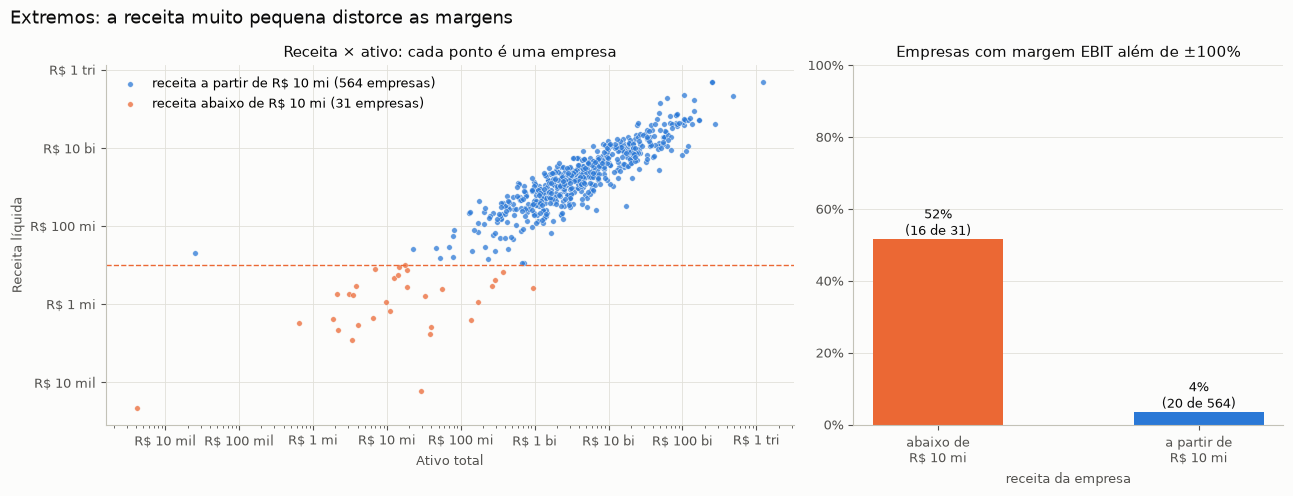

In [10]:
CORTE = segmentos.RECEITA_MINIMA
pequena = indicadores["receita"] < CORTE
margem_absurda = indicadores["margem_ebit"].abs() > 1

fig, (esq, dir_) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})

positivos = (indicadores["receita"] > 0) & (indicadores["ativo_total"] > 0)
for grupo, cor, rotulo in [(~pequena, AZUL, f"receita a partir de {reais(CORTE)}"),
                           (pequena, LARANJA, f"receita abaixo de {reais(CORTE)}")]:
    parte = indicadores[grupo & positivos]
    esq.scatter(parte["ativo_total"], parte["receita"], s=16, alpha=0.75, color=cor,
                edgecolors=FUNDO, linewidths=0.4, label=f"{rotulo} ({len(parte)} empresas)")
esq.axhline(CORTE, color=LARANJA, linestyle="--", linewidth=1)
esq.set_xscale("log")
esq.set_yscale("log")
esq.xaxis.set_major_formatter(FuncFormatter(reais))
esq.yaxis.set_major_formatter(FuncFormatter(reais))
esq.set_xlabel("Ativo total")
esq.set_ylabel("Receita líquida")
esq.set_title("Receita × ativo: cada ponto é uma empresa")
esq.legend(loc="upper left", frameon=False)

partes = {f"abaixo de\n{reais(CORTE)}": pequena, f"a partir de\n{reais(CORTE)}": ~pequena}
taxas = [margem_absurda[m].mean() if m.any() else 0.0 for m in partes.values()]
dir_.bar(list(partes), taxas, width=0.5, color=[LARANJA, AZUL])
for i, m in enumerate(partes.values()):
    dir_.text(i, taxas[i], f"{taxas[i]:.0%}\n({int(margem_absurda[m].sum())} de {int(m.sum())})",
              ha="center", va="bottom", color=TINTA)
dir_.set_ylim(0, 1)
dir_.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
dir_.set_xlabel("receita da empresa")
dir_.set_title("Empresas com margem EBIT além de ±100%")
dir_.grid(axis="x", visible=False)

fig.suptitle("Extremos: a receita muito pequena distorce as margens", x=0.01, ha="left", fontsize=13, color=TINTA)
fig.tight_layout()
salvar(fig, "eda_3_extremos.png")
plt.show()

In [11]:
print(f"As empresas com receita abaixo de {reais(CORTE)} (as 10 menores):")
menores = indicadores[pequena].sort_values("receita")[["nome", "setor", "receita", "ativo_total", "margem_ebit"]].head(10)
menores["receita"] = menores["receita"].map(reais)
menores["ativo_total"] = menores["ativo_total"].map(reais)
menores["margem_ebit"] = menores["margem_ebit"].map(lambda v: f"{v:+.0%}")
print(menores.to_string(index=False))
print(f"\nSetores das {int(pequena.sum())} empresas abaixo do corte:")
print(indicadores.loc[pequena, "setor"].value_counts().to_string())

As empresas com receita abaixo de R$ 10 mi (as 10 menores):
                                                     nome                                    setor     receita ativo_total margem_ebit
              CASA DE PEDRA SECURITIZADORA DE CREDITO S/A              Securitização de Recebíveis R$ 2,15 mil R$ 4,15 mil        -51%
                           CARBOMIL SA MINER. E INDUSTRIA                         Extração Mineral    R$ 6 mil  R$ 28,5 mi     -10917%
                             PDG COMPANHIA SECURITIZADORA              Securitização de Recebíveis  R$ 123 mil  R$ 3,37 mi       -112%
                         NOVA SOCIEDADE DE NAVEGAÇÃO S.A.         Emp. Adm. Part. - Petróleo e Gás  R$ 167 mil  R$ 37,8 mi      -7451%
SECME - COMPANHIA SECURITIZADORA DE CRÉDITOS IMOBILIÁRIOS              Securitização de Recebíveis  R$ 218 mil  R$ 2,19 mi        +55%
                                LEADS CIA. SECURITIZADORA              Securitização de Recebíveis  R$ 265 mil  R$ 38,9 mi       -

**O que o gráfico mostra.** Receita e ativo andam juntos (a nuvem sobe na diagonal); um erro de escala apareceria como um
ponto isolado, muito abaixo ou acima da nuvem (a seção seguinte procura esses casos). Abaixo do corte, cerca de metade
são securitizadoras e holdings ("Emp. Adm. Part."); com receitas de milhares de reais, a margem EBIT perde o sentido.

**Decisão (ED4, `raiox/segmentos.py`).** O K-means aprende só com as empresas a partir do corte, para elas não distorcerem
os grupos. Elas continuam na base: o vendedor ainda pode pedir o raio-x delas e ver os indicadores.

### Saltos de 1.000 vezes entre um ano e outro

Um valor declarado em "unidade" que na verdade está em "mil" fica 1.000 vezes menor. A limpeza já procura isso
(`encontrar_escala_errada`, `raiox/limpeza.py`): ela compara a receita de cada ano com a do ano **anterior** e, no
**primeiro** ano da empresa na base, a receita e o ativo com os do ano **seguinte** (issue #53). Os anos corrigidos já chegam
multiplicados por 1.000 na `contas.csv`. Aqui a busca é mais larga: receita (3.01) ou ativo (1) que mudam 500 vezes ou mais
de um ano para o outro, para cima ou para baixo, e que a limpeza deixou como estão.

In [12]:
SALTO = 500
valores = (contas[contas["cd_conta"].isin(["1", "3.01"])]
           .pivot_table(index=["nome", "cd_conta"], columns="ano", values="valor"))
anos = sorted(valores.columns)
saltos = []
for antes, depois in zip(anos, anos[1:]):
    validos = (valores[antes] > 0) & (valores[depois] > 0)
    razao = valores[depois] / valores[antes]
    for (nome, conta), r in razao[validos & ((razao >= SALTO) | (razao <= 1 / SALTO))].items():
        saltos.append({"empresa": nome, "conta": {"1": "ativo", "3.01": "receita"}[conta],
                       "de": f"{antes}: {reais(valores.loc[(nome, conta), antes])}",
                       "para": f"{depois}: {reais(valores.loc[(nome, conta), depois])}",
                       "vezes": f"{r:,.0f}x" if r >= 1 else f"1/{1 / r:,.0f}"})
saltos = pd.DataFrame(saltos, columns=["empresa", "conta", "de", "para", "vezes"])
print(f"Receita ou ativo que mudam {SALTO} vezes ou mais de um ano para o outro: {len(saltos)} casos")
saltos

Receita ou ativo que mudam 500 vezes ou mais de um ano para o outro: 5 casos


,empresa,conta,de,para,vezes
0,AZEVEDO & TRAVASSOS ENERGIA S.A.,ativo,2023: R$ 1 mil,2024: R$ 192 mi,"192,262x"
1,FASA S.A. - EM RECUPERAÇÃO JUDICIAL,ativo,"2023: R$ 25,9 mi",2024: R$ 1 mil,"1/25,946"
2,JBS N.V.,ativo,"2023: R$ 10,7 mi","2024: R$ 11,7 bi","1,084x"
3,FASA S.A. - EM RECUPERAÇÃO JUDICIAL,ativo,2024: R$ 1 mil,"2025: R$ 81,8 mi","81,814x"
4,TRV XLIII SECURITIZADORA DE CREDITOS MERCANTIS...,ativo,2024: R$ 150 mi,2025: R$ 25 mil,"1/6,004"


**Achado da EDA (04/11) e o conserto (issue #53).** O caso mais claro era a **Nova Transportadora do Sudeste (NTS)**: em 2023,
a receita *e* o ativo estavam de 1.000 a 2.000 vezes menores que em 2024 (a receita, 987 vezes; o ativo, 1.923 vezes), o sinal
típico de valores em "mil" lidos como "unidade". A limpeza não pegava porque o erro estava no **primeiro** ano da base, que não
tem ano anterior para comparar, e a NTS aparecia com crescimento de +107.154%. Agora o primeiro ano é comparado com o seguinte,
e só é corrigido quando a receita **e** o ativo estão ~1.000 vezes menores juntos: um salto só na receita pode ser uma empresa
que começou a operar. Com a NTS corrigida, o crescimento dela fica perto de +7%, e ela sai desta tabela.

O que sobra na tabela não foi corrigido, de propósito: o **JBS N.V.** tem o mesmo salto no ativo de 2023 (1.084 vezes), mas a
receita dele em 2023 é zero, então falta o segundo sinal; os outros casos (ativo de R$ 1 mil ou que cai para R$ 25 mil) podem
ser reais ou erro. Todos precisam ser olhados na CVM.

## 5. Cobertura: que anos e que setores a base tem

Se um ano tiver bem menos empresas que os outros, faltou carregar algo. E se um setor tiver poucas empresas, a comparação
"contra empresas parecidas" fica fraca para ele: é um limite que vai para a análise de ética (viés).

gravado: docs/graficos/eda_4_cobertura.png


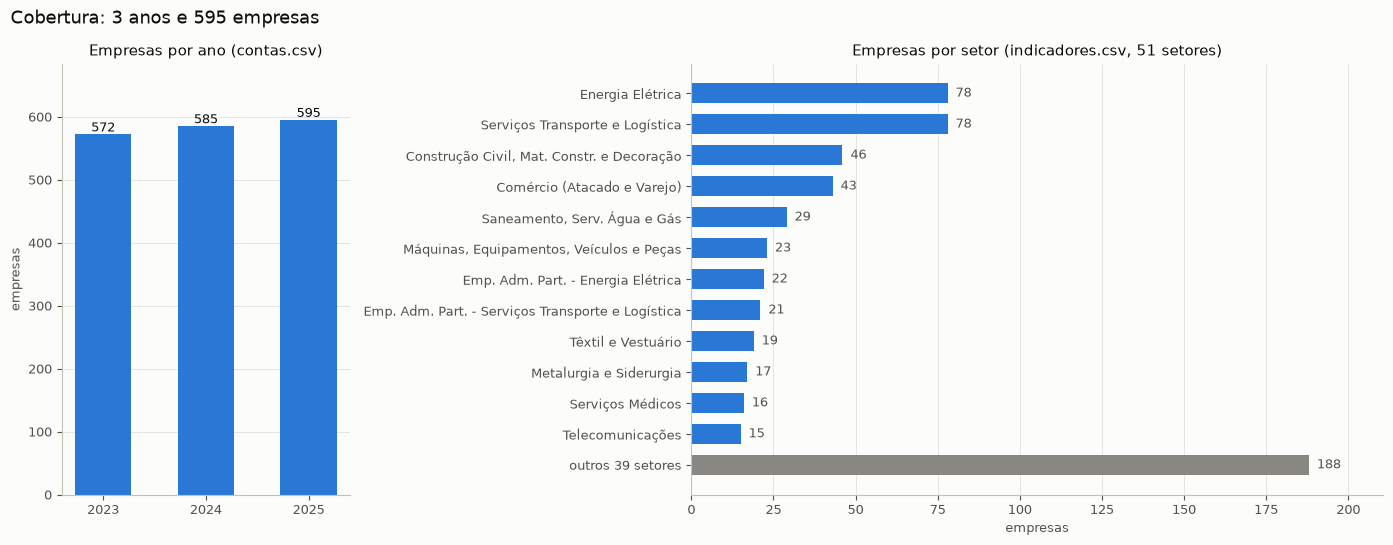

In [13]:
por_ano = contas.drop_duplicates(subset=["ano", "cd_cvm"]).groupby("ano").size()
setores = indicadores["setor"].value_counts()
MAIORES = 12
mostrar = setores.head(MAIORES)
resto = setores.iloc[MAIORES:]
if len(resto):
    mostrar = pd.concat([mostrar, pd.Series({f"outros {len(resto)} setores": int(resto.sum())})])

fig, (esq, dir_) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 2.4]})

esq.bar(por_ano.index.astype(str), por_ano.values, width=0.55, color=AZUL)
for i, v in enumerate(por_ano.values):
    esq.text(i, v, f"{v}", ha="center", va="bottom", color=TINTA)
esq.set_ylim(0, por_ano.max() * 1.15)
esq.set_ylabel("empresas")
esq.set_title("Empresas por ano (contas.csv)")
esq.grid(axis="x", visible=False)

cores = [CINZA if nome.startswith("outros") else AZUL for nome in mostrar.index]
dir_.barh(mostrar.index[::-1], mostrar.values[::-1], height=0.65, color=cores[::-1])
for i, v in enumerate(mostrar.values[::-1]):
    dir_.text(v, i, f"  {v}", va="center", color=TINTA_2)
dir_.set_xlim(0, mostrar.max() * 1.12)
dir_.set_xlabel("empresas")
dir_.set_title(f"Empresas por setor (indicadores.csv, {setores.size} setores)")
dir_.grid(axis="y", visible=False)

fig.suptitle(f"Cobertura: {len(por_ano)} anos e {len(indicadores)} empresas", x=0.01, ha="left",
             fontsize=13, color=TINTA)
fig.tight_layout()
salvar(fig, "eda_4_cobertura.png")
plt.show()

In [14]:
print("Demonstração usada (regra 5: consolidado quando existe; senão, a da própria empresa):")
print(indicadores["origem"].map({"con": "consolidado", "ind": "individual"}).value_counts().to_string())
poucas = setores[setores < 5]
print(f"\nSetores com menos de 5 empresas: {len(poucas)} de {setores.size} ({int(poucas.sum())} empresas)")

Demonstração usada (regra 5: consolidado quando existe; senão, a da própria empresa):
origem
consolidado    415
individual     180

Setores com menos de 5 empresas: 24 de 51 (52 empresas)


**O que o gráfico mostra.** Os 3 anos têm quase o mesmo número de empresas; a diferença é de empresas que passaram a reportar
à CVM depois (são elas que ficam sem crescimento, na seção 2). Os setores são bem desiguais: energia elétrica e transporte e
logística, com as holdings desses setores, são cerca de um terço da base, e muitos setores têm só um punhado de empresas.

**Decisão.** Os grupos do K-means juntam empresas pelo tamanho e pelos indicadores, e não pelo setor; assim, um setor
pequeno ainda tem com quem ser comparado. O lado ruim (o grupo pode misturar setores) já está na análise de ética
(`docs/etica.md`, seção 3: "Grupo por perfil financeiro, não por setor").

## 6. Resumo em números

Calculado agora, a partir dos dados lidos acima (por isso continua certo se a base for recarregada).

In [15]:
print(f"- Base: {len(indicadores)} empresas no indicadores.csv ({ANO}); {milhar(len(contas))} linhas de contas em "
      f"{len(por_ano)} anos ({', '.join(map(str, por_ano.index))}).")
print(f"- Nulos: só o crescimento tem vazios ({vazios['cresc_2a']} empresas: "
      f"{motivos.iloc[0]} sem receita de {ANO - 2}, {motivos.iloc[1]} com receita de {ANO - 2} zero ou negativa).")
print(f"- Distribuições: mediana da receita {reais(indicadores['receita'].median())}, "
      f"da margem EBIT {indicadores['margem_ebit'].median():.0%}, do endividamento {indicadores['endividamento'].median():.0%}.")
for coluna, (minimo, maximo) in FAIXAS.items():
    n = int(((indicadores[coluna] < minimo) | (indicadores[coluna] > maximo)).sum())
    print(f"- Extremos: {NOMES[coluna].lower()} fora de {minimo:.0%} a {maximo:.0%}: {n} empresas.")
print(f"- Corte do K-means ({reais(CORTE)}): {int(pequena.sum())} empresas abaixo, "
      f"{taxas[0]:.0%} delas com margem EBIT além de ±100% (a partir do corte: {taxas[1]:.0%}).")
print(f"- Cobertura: {setores.size} setores; os 2 maiores somam {setores.head(2).sum()} empresas; "
      f"{len(poucas)} setores com menos de 5 empresas.")

- Base: 595 empresas no indicadores.csv (2025); 384.591 linhas de contas em 3 anos (2023, 2024, 2025).
- Nulos: só o crescimento tem vazios (30 empresas: 23 sem receita de 2023, 7 com receita de 2023 zero ou negativa).
- Distribuições: mediana da receita R$ 1,68 bi, da margem EBIT 16%, do endividamento 68%.
- Extremos: crescimento em 2 anos fora de -80% a 300%: 14 empresas.
- Extremos: margem ebit fora de -100% a 100%: 36 empresas.
- Extremos: margem líquida fora de -100% a 100%: 45 empresas.
- Extremos: endividamento fora de 0% a 100%: 60 empresas.
- Corte do K-means (R$ 10 mi): 31 empresas abaixo, 52% delas com margem EBIT além de ±100% (a partir do corte: 4%).
- Cobertura: 51 setores; os 2 maiores somam 156 empresas; 24 setores com menos de 5 empresas.


## 7. O que esta análise mudou no projeto

| o que a EDA mostrou | decisão | onde está no código |
|---|---|---|
| a falta de dado é rara e tem motivo | o vazio fica vazio; nunca vira zero nem é estimado | regra 7: `raiox/limpeza.py`, `scripts/indicadores.py` |
| receita e ativo só fazem sentido em escala log; caudas longas | comparar pela mediana do grupo; K-means com o log da receita e os extremos cortados nos percentis 5 e 95 | `raiox/ia.py`, `raiox/segmentos.py` |
| extremos podem ser reais ou erro | não apagar: marcar para conferir na fonte | `raiox/checagem.py`, `avaliacao/conferencia.csv` |
| um ano inteiro de 1.000 a 2.000 vezes menor (NTS, 2023) escapava da limpeza | corrigido na limpeza, com teste (issue #53): o primeiro ano é comparado com o seguinte, pela receita e pelo ativo juntos | `encontrar_escala_errada`, `raiox/limpeza.py`; `tests/test_limpeza.py` |
| receita muito pequena dá margens sem sentido | o K-means aprende só a partir do corte de receita | `RECEITA_MINIMA`, `raiox/segmentos.py` |
| setores desiguais | grupos por perfil financeiro, não por setor; o limite está na ética | `raiox/segmentos.py`, `docs/etica.md` (seção 3) |